In [22]:
import cv2
import numpy as np

from challenge.dataset import (
    Dataset,
    create_submission,
    xywh_to_yolo,
)
from challenge.metrics import evaluate_model_with_stats
from challenge.visuals import add_yolo_boxes, plot_image_with_boxes
import matplotlib.pyplot as plt

In [11]:
test_data = Dataset("../data/data_notebook.yaml", split="test", with_labels=False)

In [39]:
import pandas as pd

df = pd.read_csv("../outputs/submission_hog_xgb_v4.csv")

In [42]:
import ast

i = 100
bbs_str = df.loc[i, "bbs"]
img, targets = test_data[i]["image"], test_data[1]["targets"]

bbs_list = ast.literal_eval(bbs_str)  # safe parsing
bbs_np = np.array(bbs_list, dtype=float)

print(bbs_np)
print(bbs_np.shape)

[[0.         0.54374999 0.3560268  0.69375002 0.5870536 ]
 [4.         0.75703126 0.22879465 0.23593751 0.25223213]]
(2, 5)


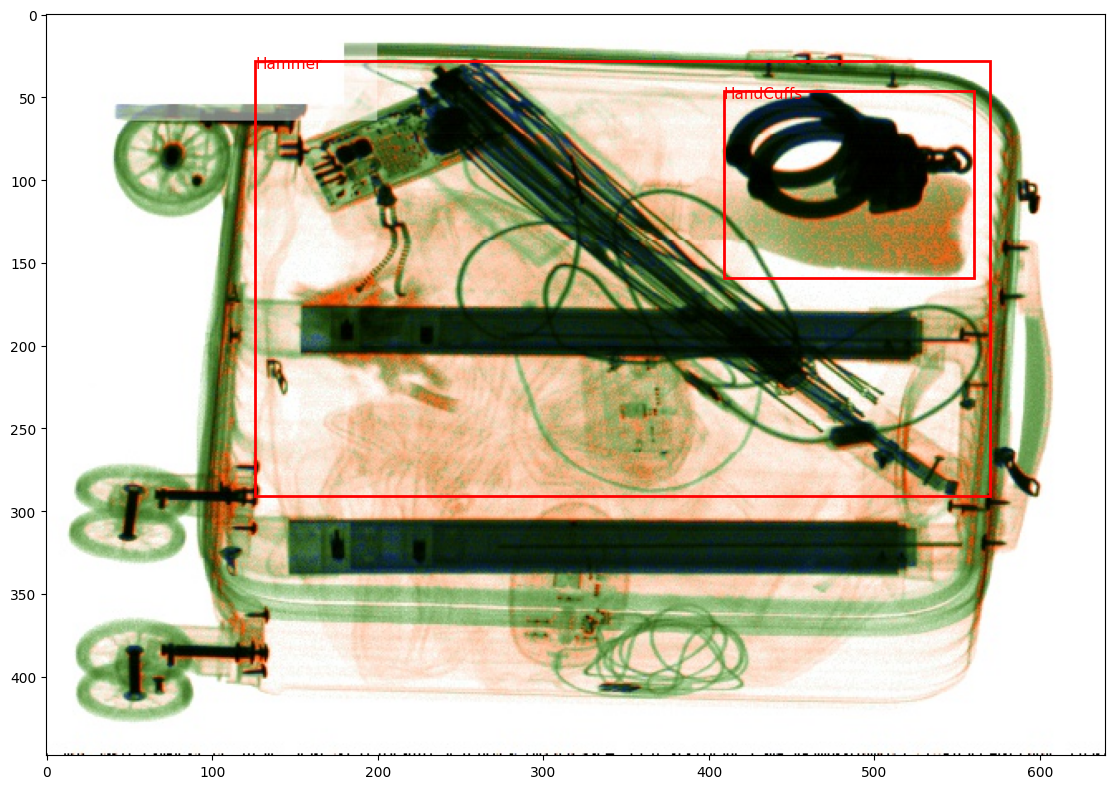

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(12, 8))
plot_image_with_boxes(
    ax,
    img,
    targets,
    color="green",
)
add_yolo_boxes(ax, bbs_np, img.shape, color="red")

plt.tight_layout()


In [15]:
a.iloc[0]

frame_id                     000a7a2a11064f729819cc43b467f28f
bbs         [[3.0, 0.5316742062568665, 0.5742574334144592,...
Name: 0, dtype: object

In [2]:
train_data = Dataset("../data/data_notebook.yaml", split="train")
val_data = Dataset("../data/data_notebook.yaml", split="val")

In [3]:
def edge_proposals(
    img: np.ndarray,
    max_boxes: int = 3,
    min_area_frac: float = 0.002,
    canny1: int = 80,
    canny2: int = 160,
) -> list[list[int]]:
    H, W = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    edges = cv2.Canny(gray, canny1, canny2)

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7))
    closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)

    cnts, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    boxes = []
    for c in cnts:
        x, y, w, h = cv2.boundingRect(c)
        area = w * h
        if area < min_area_frac * H * W:
            continue
        boxes.append((x, y, w, h))

    # Keep only biggest boxes (precision > recall)
    boxes = sorted(boxes, key=lambda b: b[2] * b[3], reverse=True)
    return boxes[:max_boxes]

In [4]:
def predict_single_class(
    loader,
    class_id: int,
    max_boxes: int = 1,
):
    preds = []

    for sample in loader:
        img = sample["image"]
        H, W = img.shape[:2]

        boxes = edge_proposals(img, max_boxes=5)  # generate more, prune later
        kept = []

        for x, y, w, h in boxes:
            kept.append((x, y, w, h))

        kept = kept[:max_boxes]

        if len(kept):
            preds.append(xywh_to_yolo(kept, img.shape, cls_id=class_id))
        else:
            preds.append(np.zeros((0, 5), dtype=np.float32))

    return preds


def merge_per_frame(preds_per_class, n_frames):
    merged_preds = []

    for i in range(n_frames):
        boxes = []
        for cls in range(6):
            p = preds_per_class[cls][i]
            if len(p) > 0:
                boxes.append(p)

        if len(boxes) > 0:
            merged = np.concatenate(boxes, axis=0)
        else:
            merged = np.zeros((0, 5), dtype=np.float32)

        merged_preds.append(merged)

    return merged_preds

In [5]:
preds_per_class = {}

for cls in range(6):
    preds_per_class[cls] = predict_single_class(val_data, class_id=cls, max_boxes=1)


merged_val_preds = merge_per_frame(
    preds_per_class,
    n_frames=len(val_data),
)

In [7]:
eval_stats = evaluate_model_with_stats(merged_val_preds, val_data, iou_threshold=0.3)

900it [00:05, 169.64it/s]


NameError: name 'val_score' is not defined

In [ ]:
from pprint import pprint

pprint(eval_stats.per_class)

{0: ClassStats(mean_iou=0.3586761685119149,
               recall=0.580110497237569,
               precision=0.11666666666666667),
 1: ClassStats(mean_iou=0.19654567178697624,
               recall=0.22018348623853212,
               precision=0.05333333333333334),
 2: ClassStats(mean_iou=0.11022380392480277,
               recall=0.05263157894736842,
               precision=0.015555555555555555),
 3: ClassStats(mean_iou=0.15233742435970768,
               recall=0.11818181818181818,
               precision=0.028888888888888888),
 4: ClassStats(mean_iou=0.21056628049714185,
               recall=0.19718309859154928,
               precision=0.04666666666666667),
 5: ClassStats(mean_iou=0.055730358150007354,
               recall=0.0045045045045045045,
               precision=0.0011111111111111111)}


In [ ]:
test_data = Dataset("../data/data_notebook.yaml", split="test", with_labels=False)

preds = []
for cls in range(6):
    preds.append(
        predict_single_class(
            test_data,
            class_id=cls,
            max_boxes=2,
        )
    )

# merge per-frame
final_preds = []
for i in range(len(test_data)):
    merged = [preds[c][i] for c in range(6)]
    merged = [m for m in merged if len(m) > 0]
    if merged:
        final_preds.append(np.concatenate(merged, axis=0))
    else:
        final_preds.append(np.zeros((0, 5), dtype=np.float32))

create_submission(
    test_data,
    final_preds,
    output_csv="../submissions/baseline_edges_v0.csv",
)

In [ ]:
create_submission(
    test_data,
    final_preds,
    output_csv="../outputs/baseline_edges_v0.csv",
)